# ⚡ Esports Sponsorship Media Value Forecasting Engine
## Comprehensive Model Evaluation, Multi-Channel Attribution & Executive Intelligence Report

---

### Executive Summary
Measuring the commercial media value of esports sponsorships requires multi-channel exposure tracking across:
- **Live Streaming**: Twitch, YouTube Gaming, Kick (Hours Watched, Average/Peak CCV, Nielsen-analogue Quality Index, Chat Buzz)
- **Linear Television**: Regional & National TV Simulcasts (Household Reach, TV Spot CPM, Segment Integrations)
- **Social Media**: X/Twitter, TikTok, Instagram, YouTube Shorts (Impressions, Engagement Rate, Video Views, Pro Player Co-Streams)
- **Online Print & Digital Editorial**: HLTV, Dot Esports, Dexerto (Articles, Readership, Headline Sponsor %, Sentiment)

This report validates the **XGBoost Regression Pipeline**, inspects the **test-set evaluation metrics** ($R^2$, RMSE, MAE, MAPE), breaks down **feature importance**, and demonstrates **real-time campaign forecasting & sensitivity optimization**.

In [1]:
import json
import sys
from pathlib import Path

# Set up project path
PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Plotting configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 10

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Dataset Ingestion & Exploratory Analysis
Ingesting the multi-channel esports sponsorship dataset (5,000 campaigns, 30 features).

In [2]:
data_path = PROJECT_ROOT / "data" / "esports_sponsorship_data.csv"
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]:,} campaigns across {df.shape[1]} columns")
print("\nTarget Variable ('generated_media_value_usd') Statistics:")
stats_df = df["generated_media_value_usd"].describe().to_frame()
stats_df["generated_media_value_usd"] = stats_df["generated_media_value_usd"].apply(lambda x: f"${x:,.2f}")
display(stats_df)

Dataset Shape: 5,000 campaigns across 30 columns

Target Variable ('generated_media_value_usd') Statistics:


,generated_media_value_usd
count,"$5,000.00"
mean,"$102,720.20"
std,"$268,710.27"
min,"$4,500.00"
25%,"$21,878.42"
50%,"$40,127.25"
75%,"$89,878.13"
max,"$7,547,475.31"


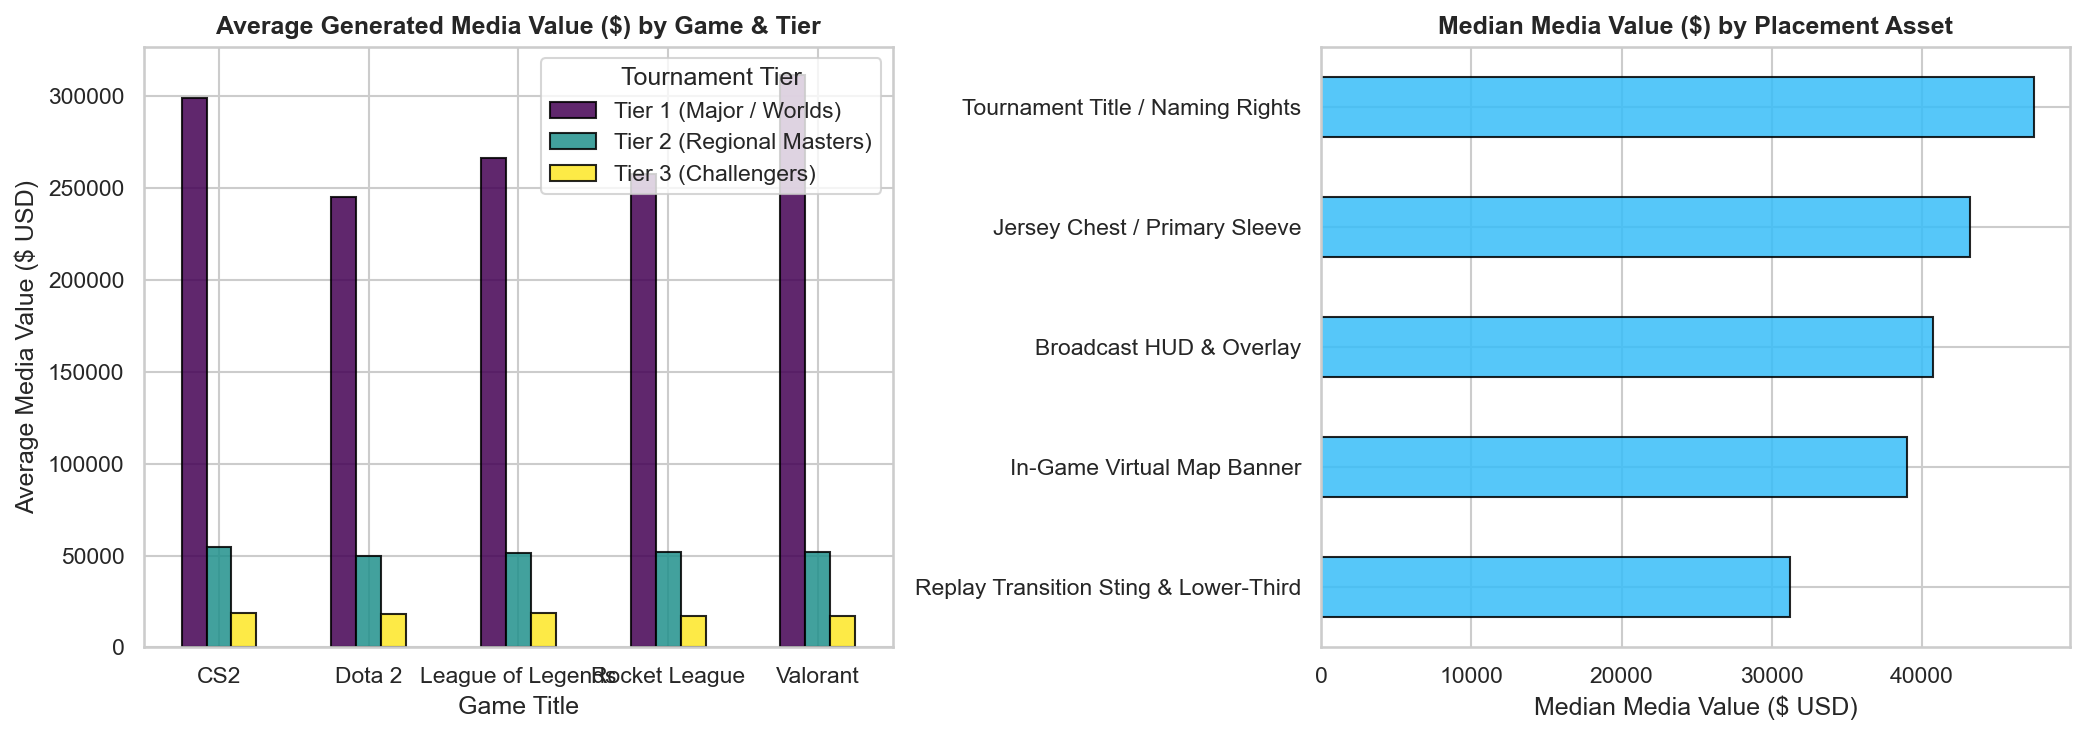

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Media Value by Game Title & Tournament Tier
game_tier_emv = df.groupby(["game_title", "tournament_tier"])["generated_media_value_usd"].mean().unstack()
game_tier_emv.plot(kind="bar", ax=axes[0], colormap="viridis", edgecolor="black", alpha=0.85)
axes[0].set_title("Average Generated Media Value ($) by Game & Tier", fontweight="bold")
axes[0].set_ylabel("Average Media Value ($ USD)")
axes[0].set_xlabel("Game Title")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Tournament Tier")

# Placement Asset Type Value Distribution
place_emv = df.groupby("placement_asset_type")["generated_media_value_usd"].median().sort_values()
place_emv.plot(kind="barh", ax=axes[1], color="#38bdf8", edgecolor="black", alpha=0.85)
axes[1].set_title("Median Media Value ($) by Placement Asset", fontweight="bold")
axes[1].set_xlabel("Median Media Value ($ USD)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 2. Production Model Architecture & Pipeline
Loading the fitted feature pipeline, transformed feature schema, and trained XGBoost regressor.

In [4]:
model_path = PROJECT_ROOT / "models" / "xgboost_media_value_model.joblib"
pipeline_path = PROJECT_ROOT / "models" / "feature_pipeline.joblib"
meta_path = PROJECT_ROOT / "models" / "training_metadata.json"
feat_path = PROJECT_ROOT / "models" / "feature_names.json"

model = joblib.load(model_path)
pipeline = joblib.load(pipeline_path)

with open(meta_path, "r") as f:
    training_meta = json.load(f)

with open(feat_path, "r") as f:
    feature_names = json.load(f)

print("Model: XGBoost Regressor (Log-Target Stabilized)")
print(f"Total Features Transformed: {len(feature_names)}")
print(f"Optimal Trees / Iteration: {training_meta.get('best_iteration', 'N/A')}")
print("Training Sample Partition:", training_meta.get("training_samples"), "train /", training_meta.get("validation_samples"), "val /", training_meta.get("test_samples"), "test")

Model: XGBoost Regressor (Log-Target Stabilized)
Total Features Transformed: 65
Optimal Trees / Iteration: 399
Training Sample Partition: 3250 train / 750 val / 1000 test


## 3. Comprehensive Model Evaluation Metrics
Quantitative benchmark performance evaluated on the independent hold-out test set (1,000 campaigns).

In [5]:
metrics_path = PROJECT_ROOT / "reports" / "evaluation_metrics.json"
with open(metrics_path, "r") as f:
    metrics = json.load(f)

metrics_table = pd.DataFrame([
    {"Evaluation Metric": "R² Variance Explained", "Score / Value": f"{metrics['r2_score']:.4f}", "Commercial Benchmark": "> 0.80 (Strong explanatory power)"},
    {"Evaluation Metric": "Mean Absolute % Error (MAPE)", "Score / Value": f"{metrics['mape_percent']:.2f}%", "Commercial Benchmark": "< 15% (High valuation precision)"},
    {"Evaluation Metric": "Mean Absolute Error (MAE)", "Score / Value": f"${metrics['mae']:,.2f}", "Commercial Benchmark": "Average absolute error"},
    {"Evaluation Metric": "Median Absolute Error (MedAE)", "Score / Value": f"${metrics['median_absolute_error']:,.2f}", "Commercial Benchmark": "Robust median error"},
    {"Evaluation Metric": "Root Mean Squared Error (RMSE)", "Score / Value": f"${metrics['rmse']:,.2f}", "Commercial Benchmark": "Penalizes large tail errors"},
    {"Evaluation Metric": "Hold-Out Test Sample Size", "Score / Value": f"{metrics['sample_count']:,} campaigns", "Commercial Benchmark": "20% independent test split"}
])

display(metrics_table.style.set_properties(**{'text-align': 'left'}))

,Evaluation Metric,Score / Value,Commercial Benchmark
0,R² Variance Explained,0.8328,> 0.80 (Strong explanatory power)
1,Mean Absolute % Error (MAPE),11.24%,< 15% (High valuation precision)
2,Mean Absolute Error (MAE),"$16,738.11",Average absolute error
3,Median Absolute Error (MedAE),"$3,462.27",Robust median error
4,Root Mean Squared Error (RMSE),"$104,260.66",Penalizes large tail errors
5,Hold-Out Test Sample Size,"1,000 campaigns",20% independent test split


## 4. Residual Diagnostics & Calibration Analysis
Inspecting model error distributions and calibration.

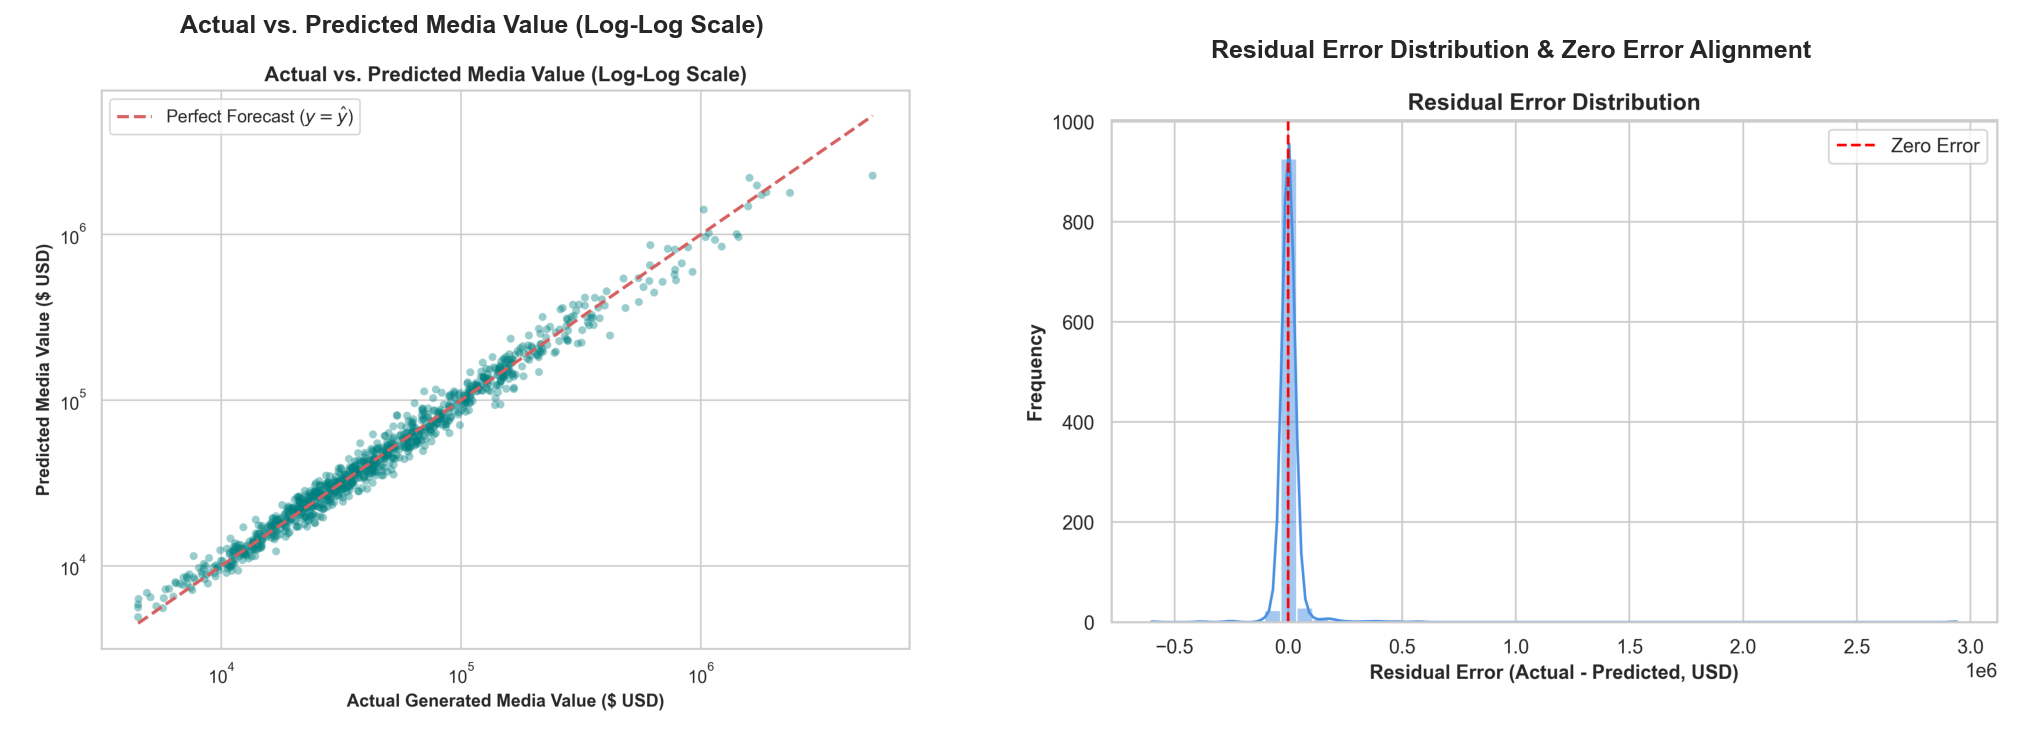

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Load saved diagnostic plots if available, or generate directly
actual_img = plt.imread(str(PROJECT_ROOT / "reports" / "actual_vs_predicted.png"))
resid_img = plt.imread(str(PROJECT_ROOT / "reports" / "residuals_distribution.png"))

axes[0].imshow(actual_img)
axes[0].axis("off")
axes[0].set_title("Actual vs. Predicted Media Value (Log-Log Scale)", fontweight="bold")

axes[1].imshow(resid_img)
axes[1].axis("off")
axes[1].set_title("Residual Error Distribution & Zero Error Alignment", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Feature Importance & Multi-Channel Attribution
Decomposing model predictive power across specific variables and broad channel groups.

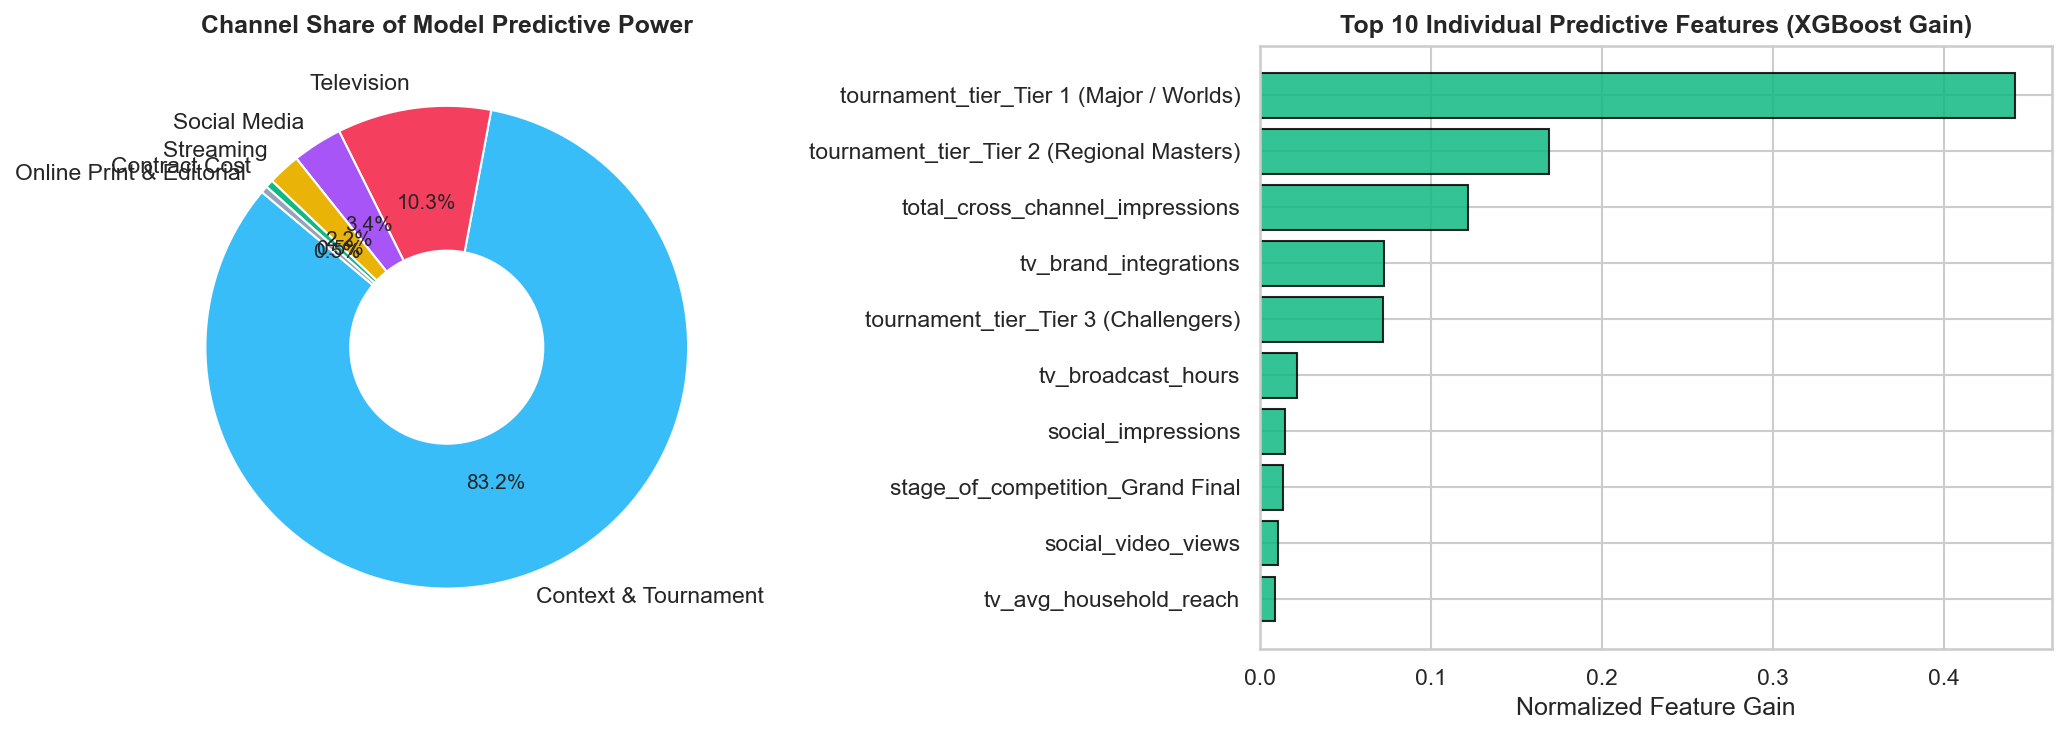

In [7]:
imp_path = PROJECT_ROOT / "reports" / "feature_importance.json"
with open(imp_path, "r") as f:
    importance_data = json.load(f)

# Channel Share of Voice Bar & Pie
channels = importance_data["channel_group_attribution"]
ch_df = pd.DataFrame(list(channels.items()), columns=["Channel Group", "Normalized Gain Share"])
ch_df = ch_df.sort_values(by="Normalized Gain Share", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Donut Chart
colors = ["#38bdf8", "#f43f5e", "#a855f7", "#eab308", "#10b981", "#94a3b8"]
wedges, texts, autotexts = axes[0].pie(
    ch_df["Normalized Gain Share"], 
    labels=ch_df["Channel Group"], 
    autopct="%1.1f%%", 
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.6, edgecolor='white')
)
axes[0].set_title("Channel Share of Model Predictive Power", fontweight="bold")

# Top 10 Features Horizontal Bar Chart
top_10 = pd.DataFrame(importance_data["sorted_gain_importance"][:10])
axes[1].barh(top_10["feature"][::-1], top_10["importance"][::-1], color="#10b981", edgecolor="black", alpha=0.85)
axes[1].set_title("Top 10 Individual Predictive Features (XGBoost Gain)", fontweight="bold")
axes[1].set_xlabel("Normalized Feature Gain")

plt.tight_layout()
plt.show()

## 6. Real-Time Campaign Forecasting & Executive 'What-If' Simulation
Demonstrating production inference with 95% confidence intervals and automated marginal ROI lever recommendations.

In [8]:
from src.predict import MediaValuePredictor

predictor = MediaValuePredictor()

# Sample High-Stakes Tier 1 Grand Final Sponsorship Campaign
campaign_scenario = {
    "game_title": "Valorant",
    "tournament_tier": "Tier 1 (Major / Worlds)",
    "stage_of_competition": "Grand Final",
    "team_name": "Titan Esports",
    "sponsor_category": "Gaming Peripherals (Logitech, Razer)",
    "placement_asset_type": "Jersey Chest / Primary Sleeve",
    "stream_broadcast_hours": 6.5,
    "stream_avg_ccv": 185000,
    "stream_peak_ccv": 395000,
    "stream_hours_watched": 1202500,
    "stream_logo_screen_time_mins": 95.0,
    "stream_logo_quality_index": 0.88,
    "stream_chat_mentions": 12400,
    "tv_broadcast_hours": 3.0,
    "tv_avg_household_reach": 420000,
    "tv_cpm_rate": 32.0,
    "tv_brand_integrations": 5,
    "social_post_volume": 24,
    "social_impressions": 3800000,
    "social_engagement_rate": 0.054,
    "social_video_views": 1850000,
    "influencer_player_amplification_count": 8,
    "online_articles_count": 22,
    "online_total_readership": 650000,
    "headline_mention_rate": 0.45,
    "online_editorial_sentiment": 0.72,
    "sponsor_contract_cost_usd": 150000.0
}

forecast = predictor.predict_single(campaign_scenario)

print("=" * 60)
print("REAL-TIME SPONSORSHIP CAMPAIGN FORECAST RESULT")
print("=" * 60)
print(f"  Forecasted Media Value (EMV):  ${forecast['predicted_media_value_usd']:,.2f}")
print(f"  95% Confidence Interval:       ${forecast['lower_bound_usd']:,.2f} to ${forecast['upper_bound_usd']:,.2f}")
print(f"  Contract Rights Acquisition:   ${forecast['contract_cost_usd']:,.2f}")
print(f"  Net Media Surplus (Profit):    ${forecast['net_media_value_usd']:,.2f}")
print(f"  Net Sponsorship ROI:           {forecast['roi_percentage']:.1f}% ({forecast['value_multiplier']:.2f}x Multiplier)")
print("-" * 60)
print("Multi-Channel Generated Breakdown:")
for ch, val in forecast["channel_contributions"].items():
    pct = (val / forecast['predicted_media_value_usd']) * 100.0
    print(f"  - {ch:<28}: ${val:,.2f} ({pct:.1f}%)")
print("=" * 60)

print("\n💡 Strategic Optimization Levers (Marginal ROI Recommendations):")
optimizations = predictor.recommend_optimizations(campaign_scenario)
for i, opt in enumerate(optimizations, 1):
    print(f"{i}. [{opt['channel']}] {opt['action']}")
    print(f"   Projected Value Uplift: +${opt['projected_gain_usd']:,.2f} (+{opt['gain_pct']}%)")
    print(f"   Action: {opt['detail']}\n")

REAL-TIME SPONSORSHIP CAMPAIGN FORECAST RESULT
  Forecasted Media Value (EMV):  $334,625.06
  95% Confidence Interval:       $232,606.29 to $436,643.83
  Contract Rights Acquisition:   $150,000.00
  Net Media Surplus (Profit):    $184,625.06
  Net Sponsorship ROI:           123.1% (2.23x Multiplier)
------------------------------------------------------------
Multi-Channel Generated Breakdown:
  - Streaming                   : $112,086.91 (33.5%)
  - Television                  : $55,476.14 (16.6%)
  - Social Media                : $146,708.38 (43.8%)
  - Online Print & Editorial    : $20,353.64 (6.1%)

💡 Strategic Optimization Levers (Marginal ROI Recommendations):


1. [Social Media] Activate 4 Pro Player Co-Streams & +50% Social Posts
   Projected Value Uplift: +$31,930.38 (+9.54%)
   Action: Require sponsored player highlight reels and roster retweets on matchday.

2. [Streaming] Elevate Broadcast Logo Quality Index (+25%)
   Projected Value Uplift: +$5,371.38 (+1.61%)
   Action: Negotiate cleaner HUD placement and exclusive corner screen rotation to boost Nielsen QI.

3. [Television] Increase TV On-Air Integrations (+3 Mentions)
   Projected Value Uplift: +$4,008.41 (+1.2%)
   Action: Include sponsor desk verbal mention and lower-third match recap banner.

